# EDA 3: California Housing
**Source:** StatLib, loaded with `sklearn.datasets.fetch_california_housing`


California Housing comes from the 1990 US Census (Pace & Barry, 1997). Each row is a block group (a small area of a few hundred to a few thousand people), and the target is the median house value in that area.
TabDDPM (Kotelnikov et al., 2023) uses it as one of its regression benchmarks.

We include it because it is different from the other two datasets:
- it is a **regression** task, so the utility test uses regression metrics (R², RMSE) instead of accuracy/F1
- all columns are numeric, so it isolates how well generators handle continuous columns
- several columns are capped (top-coded), which creates spikes at the maximum value
- latitude and longitude form a geographic structure that is easy to plot and check

**What this notebook produces:** a summary row for the report table, figures in `figures/eda/` and
preprocessing notes for M2.

## 1. Setup

Imports, folder paths and plot settings. The notebook works whether you open it from the repo root
or from the `notebooks/` folder, because the root folder is worked out from the current directory.

Outputs go to three folders (created if they don't exist):

- `data/raw/`: a local copy of the downloaded data, so the download only happens once
- `figures/eda/`: PNG figures for the report
- `results/eda/`: the summary table as a CSV

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Find the repo root (this notebook lives in notebooks/)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = ROOT / "data" / "raw"
FIG_DIR = ROOT / "figures" / "eda"
RES_DIR = ROOT / "results" / "eda"
for folder in (RAW_DIR, FIG_DIR, RES_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# Plot style: one blue for single-colour plots, blue/orange for the two classes
BLUE, ORANGE = "#2a78d6", "#eb6834"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 200
plt.rcParams["savefig.bbox"] = "tight"
pd.set_option("display.max_columns", 50)

print("Repo root:", ROOT)

Repo root: c:\Users\Admin\OneDrive\Desktop\MS DS 1\DS lab 1\EDA & Milestone 1\dslab1_synthetic_data


## 2. Load the data

scikit-learn downloads the data once and keeps it in its own cache folder (`~/scikit_learn_data`).
We also save a copy to `data/raw/` so all three datasets are in the same place.

The scikit-learn version is already slightly processed compared with the raw census file: the room,
bedroom and occupancy columns are averages *per household* (for example `AveRooms` = total rooms in the
block / number of households), and the target is in units of 100,000 dollars.

In [2]:
from sklearn.datasets import fetch_california_housing

cache_file = RAW_DIR / "california_housing.csv"

if cache_file.exists():
    df = pd.read_csv(cache_file)
    print("Loaded local copy:", cache_file)
else:
    df = fetch_california_housing(as_frame=True).frame
    df.to_csv(cache_file, index=False)
    print("Downloaded with scikit-learn and saved to", cache_file)

print("Shape:", df.shape)
df.head()

Downloaded with scikit-learn and saved to c:\Users\Admin\OneDrive\Desktop\MS DS 1\DS lab 1\EDA & Milestone 1\dslab1_synthetic_data\data\raw\california_housing.csv
Shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


## 3. Column types and missing values

| Column | Meaning |
|---|---|
| MedInc | median income in the block (in 10,000 dollars) |
| HouseAge | median house age (years) |
| AveRooms | average rooms per household |
| AveBedrms | average bedrooms per household |
| Population | people living in the block |
| AveOccup | average people per household |
| Latitude, Longitude | location of the block |
| MedHouseVal | **target**: median house value (in 100,000 dollars) |

In [3]:
TARGET = "MedHouseVal"
num_cols = df.drop(columns=TARGET).columns.tolist()
cat_cols = []

print(df.dtypes.value_counts())
print("Missing cells:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

float64    9
Name: count, dtype: int64
Missing cells: 0
Duplicate rows: 0


All 9 columns are numeric and nothing is missing.

## 4. Summary statistics

Compare the 99th percentile with the maximum: if the maximum is many times larger, the column has extreme
outliers.

In [4]:
stats = df.describe(percentiles=[0.01, 0.5, 0.99]).T
stats["skew"] = df.skew()
stats["max / p99"] = stats["max"] / stats["99%"]
stats.round(2)

,count,mean,std,min,1%,50%,99%,max,skew,max / p99
MedInc,20640.0,3.87,1.90,0.50,1.07,3.53,10.60,15.00,1.65,1.42
HouseAge,20640.0,28.64,12.59,1.00,4.00,29.00,52.00,52.00,0.06,1.00
AveRooms,20640.0,5.43,2.47,0.85,2.58,5.23,10.36,141.91,20.70,13.70
AveBedrms,20640.0,1.10,0.47,0.33,0.87,1.05,2.13,34.07,31.32,16.01
Population,20640.0,1425.48,1132.46,3.00,88.00,1166.00,5805.83,35682.00,4.94,6.15
AveOccup,20640.0,3.07,10.39,0.69,1.54,2.82,5.39,1243.33,97.64,230.47
Latitude,20640.0,35.63,2.14,32.54,32.68,34.26,40.63,41.95,0.47,1.03
Longitude,20640.0,-119.57,2.00,-124.35,-123.22,-118.49,-116.29,-114.31,-0.30,0.98
MedHouseVal,20640.0,2.07,1.15,0.15,0.50,1.80,5.00,5.00,0.98,1.00


`AveRooms`, `AveBedrms`, `Population` and `AveOccup` all have maxima far above their 99th percentile
(for `AveOccup` the maximum is over 1,000 people per household, which is not realistic and probably comes
from blocks with very few households, such as dormitories or institutions).

## 5. Capped values

The census data was top-coded: house values above 500,000 dollars were stored as 500,001, and house ages
above 52 were stored as 52. This shows up as a spike at the maximum.

In [5]:
for col in ["MedHouseVal", "HouseAge"]:
    top = df[col].max()
    n_top = (df[col] == top).sum()
    print(f"{col}: max = {top}, rows at the max = {n_top} ({n_top / len(df):.1%})")

MedHouseVal: max = 5.00001, rows at the max = 965 (4.7%)
HouseAge: max = 52.0, rows at the max = 1273 (6.2%)


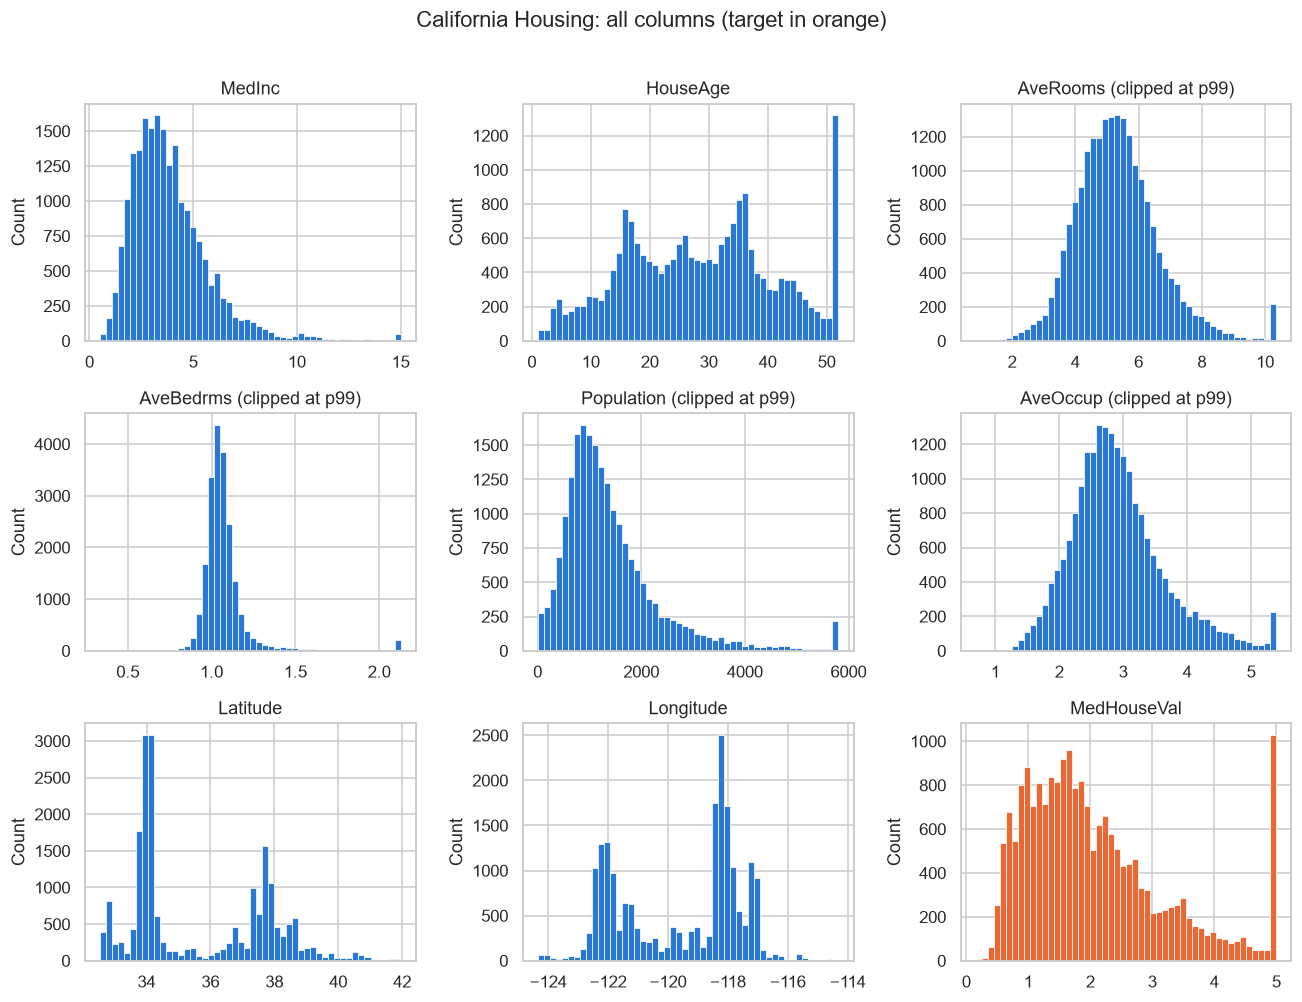

In [6]:
fig, axes = plt.subplots(3, 3, figsize=(12, 9))
for ax, col in zip(axes.ravel(), df.columns):
    data = df[col]
    # clip the extreme columns at the 99th percentile for the plot only, so the shape is visible
    clipped = col in ("AveRooms", "AveBedrms", "Population", "AveOccup")
    if clipped:
        data = data.clip(upper=data.quantile(0.99))
    ax.hist(data, bins=50, color=ORANGE if col == TARGET else BLUE, edgecolor="white", linewidth=0.5)
    ax.set_title(col + (" (clipped at p99)" if clipped else ""))
    ax.set_ylabel("Count")
fig.suptitle("California Housing: all columns (target in orange)", y=1.01)
fig.tight_layout()
fig.savefig(FIG_DIR / "california_distributions.png")
plt.show()

What stands out:
- `MedHouseVal` (the target) has a clear spike at the cap, and `HouseAge` has one at 52.
  A generator that learns a smooth density will blur these spikes or produce values above the cap.
- `Latitude` and `Longitude` are bimodal: the two peaks are the Los Angeles and San Francisco Bay areas.
- `MedInc` is right-skewed but much better behaved than the per-household averages.

## 6. Geography

Plotting the blocks on their coordinates shows the coastline and the expensive coastal areas. This is a
quick visual test for synthetic data later: if the synthetic points fall in the sea, the generator did not
learn the joint distribution of latitude and longitude.

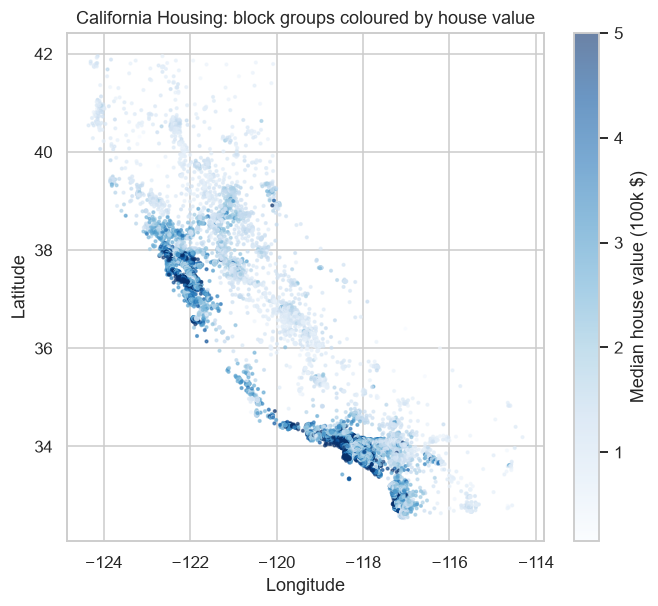

In [7]:
fig, ax = plt.subplots(figsize=(7, 6))
points = ax.scatter(df["Longitude"], df["Latitude"], c=df[TARGET], cmap="Blues", s=3, alpha=0.6)
fig.colorbar(points, ax=ax, label="Median house value (100k $)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("California Housing: block groups coloured by house value")
fig.savefig(FIG_DIR / "california_map.png")
plt.show()

## 7. Correlations

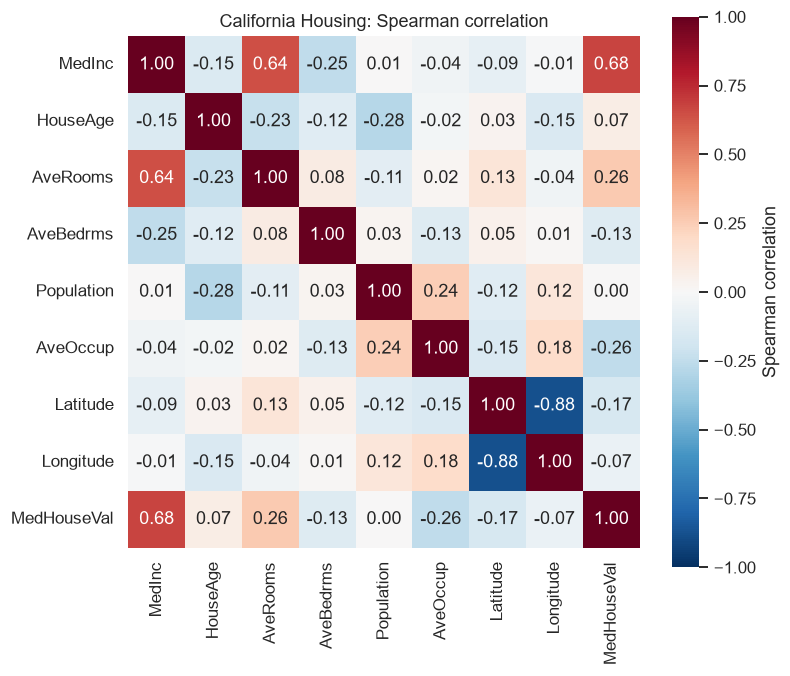

In [8]:
spearman = df.corr(method="spearman")

fig, ax = plt.subplots(figsize=(7.5, 6.5))
sns.heatmap(spearman, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, ax=ax,
            cbar_kws={"label": "Spearman correlation"})
ax.set_title("California Housing: Spearman correlation")
fig.savefig(FIG_DIR / "california_spearman.png")
plt.show()

In [9]:
print("Correlation with the target:")
print(spearman[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(2))

Correlation with the target:
MedInc        0.68
AveRooms      0.26
AveOccup     -0.26
Latitude     -0.17
AveBedrms    -0.13
HouseAge      0.07
Longitude    -0.07
Population    0.00
Name: MedHouseVal, dtype: float64


`MedInc` is by far the strongest predictor of house value, and it also goes together with `AveRooms`
(richer areas have bigger homes). `Latitude` and `Longitude` are strongly negatively correlated with each
other, because the state runs from north-west to south-east. These pairs are the dependencies to check in
the synthetic data.

## 8. Summary for the report

In [10]:
summary = pd.DataFrame([{
    "dataset": "California Housing",
    "rows": len(df),
    "cols": df.shape[1],
    "numeric": len(num_cols),
    "categorical": len(cat_cols),
    "target": "house value (regression)",
    "minority_share": None,
    "rows_with_missing": int(df.isna().any(axis=1).sum()),
    "missing_note": "none; target capped at 5.00001, HouseAge capped at 52",
}])
summary.to_csv(RES_DIR / "california_summary.csv", index=False)

s = summary.iloc[0]
print(f"California Housing & {s.rows:,} & {s.cols} & {s.numeric} & {s.categorical} & "
      f"house value & none \\\\")
summary

California Housing & 20,640 & 9 & 8 & 0 & house value & none \\


,dataset,rows,cols,numeric,categorical,target,minority_share,rows_with_missing,missing_note
0,California Housing,20640,9,8,0,house value (regression),None,0,"none; target capped at 5.00001, HouseAge cappe..."
